In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

## Data Loading and Exploratory Data Analysis

In [2]:
df = pd.read_csv('data/basketball_shooting_dataset.csv')
df.head()

,Player_ID,Age,Height_cm,Weight_kg,Shot_Type,Shot_Result,Distance_from_Basket_m,Shot_Angle_deg,Accelerometer_X_m_s2,Accelerometer_Y_m_s2,Accelerometer_Z_m_s2,Gyroscope_X_deg_s,Gyroscope_Y_deg_s,Gyroscope_Z_deg_s,Shot_Speed_m_s,Release_Angle_deg,Release_Timing_ms,Follow_Through_Angle_deg,Arc_Radius_m,Timestamp
0,P001,32,178,65,Set Shot,1,4.39,34.61,1.30,0.59,0.79,-47.00,-92.95,59.68,4.95,48.09,424,27.30,1.63,2025-01-31 13:55:35
1,P002,18,187,66,Layup,0,4.76,28.43,1.36,-0.39,1.06,298.16,2.78,125.66,5.73,59.79,581,34.85,1.82,2025-01-31 13:45:35
2,P003,29,192,82,Layup,0,3.31,34.91,-1.30,-0.31,-0.34,-20.27,111.69,-162.72,4.77,45.40,364,24.97,1.84,2025-01-31 13:35:35
3,P004,31,190,66,Set Shot,0,7.07,12.93,-1.44,-0.44,-0.65,197.73,248.18,-46.79,4.70,54.74,470,13.10,1.90,2025-01-31 13:25:35
4,P005,29,200,93,Jump Shot,1,5.21,19.76,-0.27,1.09,-1.43,35.74,-138.71,-43.75,4.42,39.50,510,33.29,1.74,2025-01-31 13:15:35


In [3]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 1000):
    display(df.groupby('Shot_Result').describe().T)

Shot_Result                              0           1
Age                      count  152.000000  148.000000
                         mean    26.578947   26.567568
                         std      5.185980    5.206174
                         min     18.000000   18.000000
                         25%     22.000000   22.000000
                         50%     27.000000   26.000000
                         75%     31.250000   31.000000
                         max     35.000000   35.000000
Height_cm                count  152.000000  148.000000
                         mean   185.625000  184.628378
                         std      8.764628    8.899500
                         min    170.000000  170.000000
                         25%    177.750000  176.000000
                         50%    185.500000  185.000000
                         75%    193.000000  191.250000
                         max    200.000000  200.000000
Weight_kg                count  152.000000  148.000000
                         mean    80.651316   79.756757
                         std     11.415836   11.594992
                         min     60.000000   60.000000
                         25%     71.500000   69.000000
                         50%     81.000000   80.000000
                         75%     90.000000   89.250000
                         max    100.000000   99.000000
Distance_from_Basket_m   count  152.000000  148.000000
                         mean     4.211118    4.187568
                         std      1.959868    1.795209
                         min      1.160000    1.180000
                         25%      2.357500    2.817500
                         50%      4.380000    3.865000
                         75%      5.992500    5.697500
                         max      7.430000    7.420000
Shot_Angle_deg           count  152.000000  148.000000
                         mean    50.570921   52.702703
                         std     23.143301   22.566113
                         min     11.260000   10.950000
                         25%     30.800000   32.462500
                         50%     49.525000   51.955000
                         75%     71.082500   73.597500
                         max     89.850000   89.850000
Accelerometer_X_m_s2     count  152.000000  148.000000
                         mean     0.049803   -0.054797
                         std      0.783897    0.887105
                         min     -1.440000   -1.490000
                         25%     -0.647500   -0.787500
                         50%      0.170000    0.030000
                         75%      0.720000    0.682500
                         max      1.470000    1.490000
Accelerometer_Y_m_s2     count  152.000000  148.000000
                         mean    -0.028289   -0.004730
                         std      0.870636    0.863815
                         min     -1.480000   -1.470000
                         25%     -0.727500   -0.715000
                         50%     -0.100000    0.075000
                         75%      0.722500    0.650000
                         max      1.490000    1.470000
Accelerometer_Z_m_s2     count  152.000000  148.000000
                         mean    -0.107105   -0.029797
                         std      0.894575    0.907742
                         min     -1.480000   -1.500000
                         25%     -0.882500   -0.912500
                         50%     -0.095000   -0.085000
                         75%      0.655000    0.800000
                         max      1.500000    1.500000
Gyroscope_X_deg_s        count  152.000000  148.000000
                         mean   -15.058750    5.334324
                         std    184.223504  171.010215
                         min   -292.830000 -295.020000
                         25%   -179.015000 -135.292500
                         50%    -30.310000   -7.000000
                         75%    139.990000  158.482500
                         max    298.1600

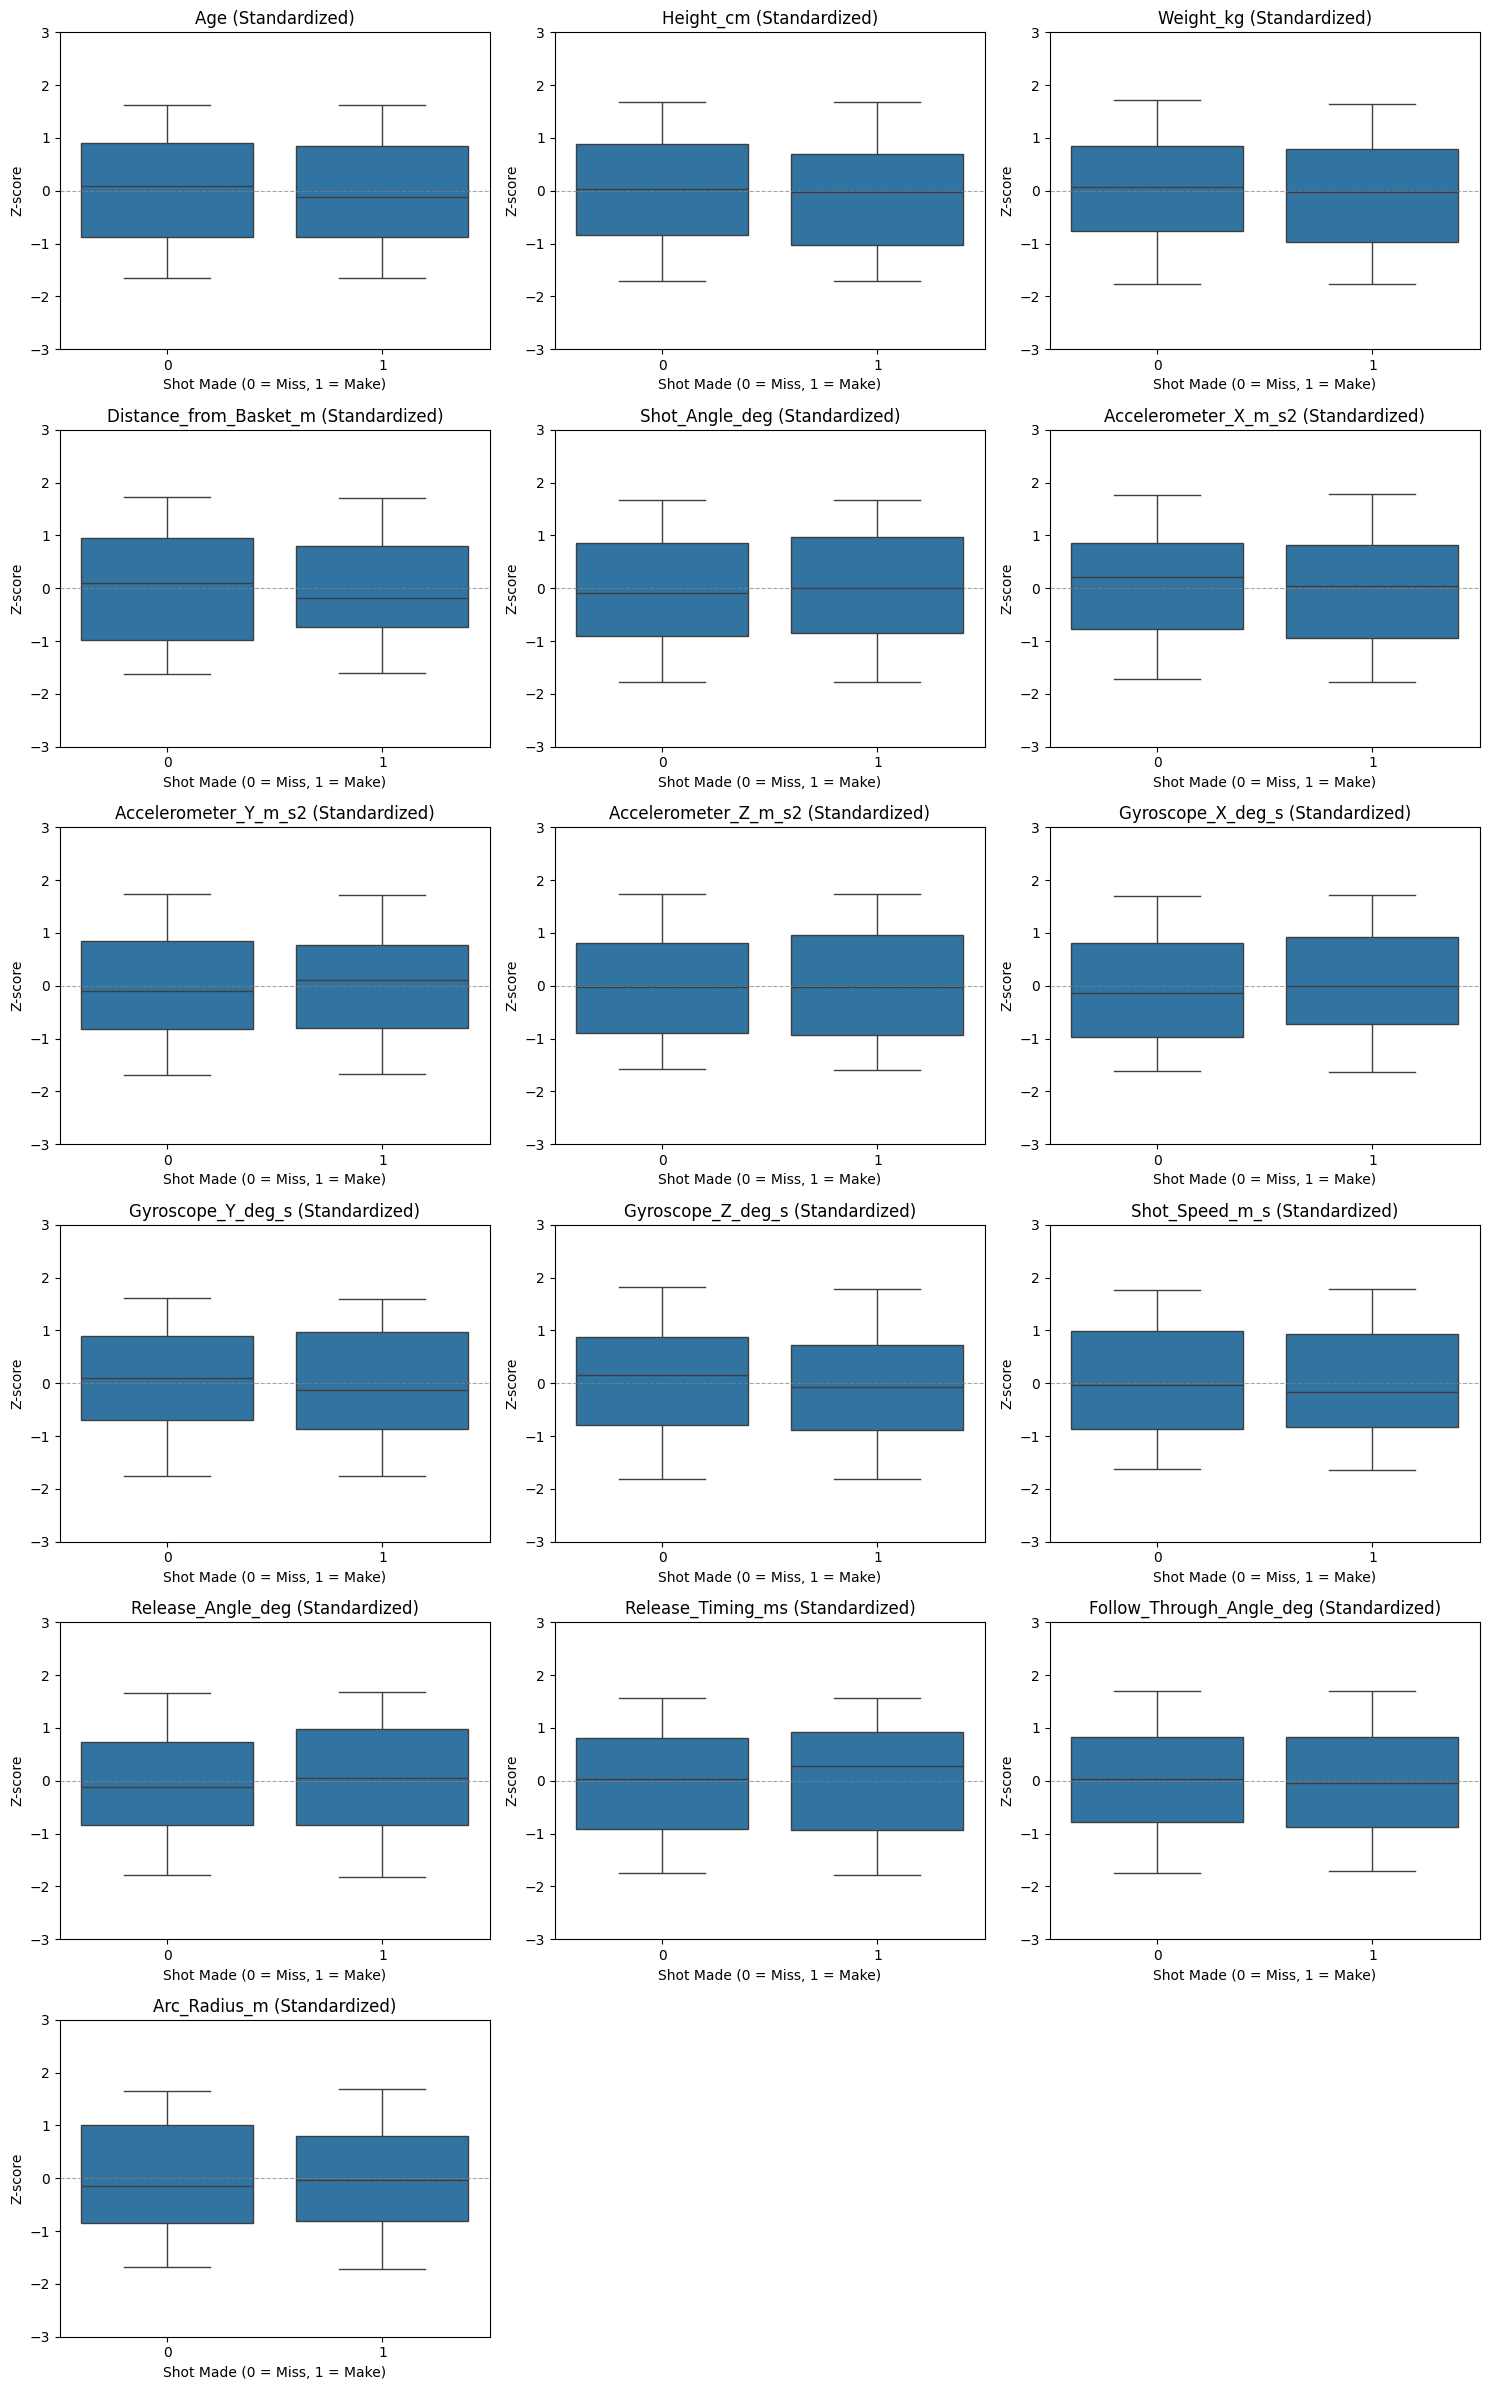

In [4]:
numeric_cols = [col for col in df.select_dtypes(include='number').columns if col != 'Shot_Result']

df_std = df[['Shot_Result'] + numeric_cols].copy()
df_std[numeric_cols] = (df_std[numeric_cols] - df_std[numeric_cols].mean()) / df_std[numeric_cols].std()

n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(x='Shot_Result', y=col, data=df_std, ax=axes[idx], showfliers=True)
    axes[idx].axhline(0, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)
    axes[idx].set_ylim(-3, 3)
    axes[idx].set_title(f'{col} (Standardized)')
    axes[idx].set_xlabel('Shot Made (0 = Miss, 1 = Make)')
    axes[idx].set_ylabel('Z-score')

for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<Axes: >

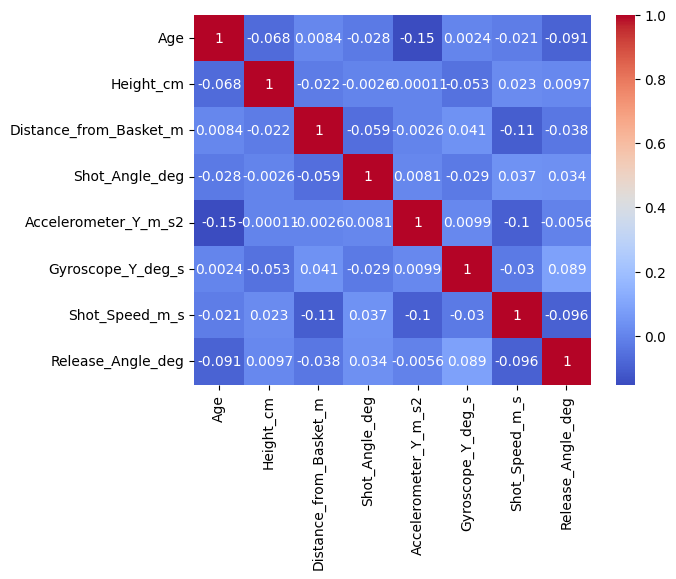

In [5]:
candidates = ['Age', 'Height_cm', 'Distance_from_Basket_m', 'Shot_Angle_deg', 'Accelerometer_Y_m_s2', 'Gyroscope_Y_deg_s', 'Shot_Speed_m_s', 'Release_Angle_deg']

sns.heatmap(df[candidates].corr(), annot=True, cmap='coolwarm')

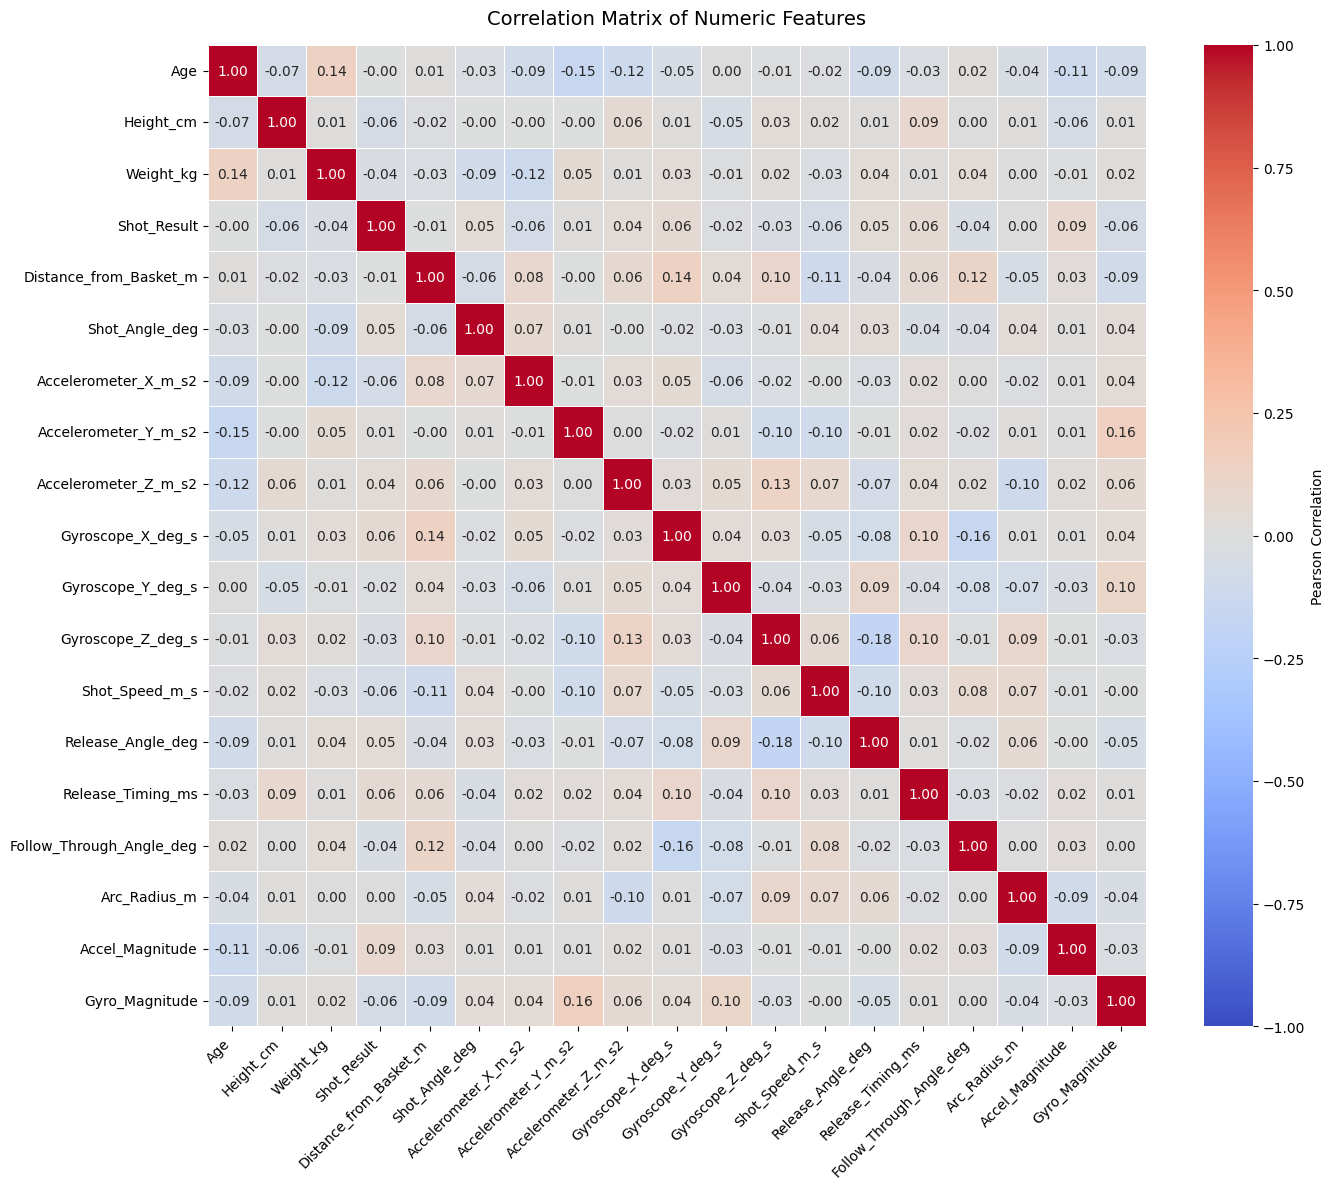

In [6]:
# Compute sensor vector magnitudes once for downstream modeling
accel_axes = ['Accelerometer_X_m_s2', 'Accelerometer_Y_m_s2', 'Accelerometer_Z_m_s2']
gyro_axes = ['Gyroscope_X_deg_s', 'Gyroscope_Y_deg_s', 'Gyroscope_Z_deg_s']

df['Accel_Magnitude'] = np.sqrt(np.square(df[accel_axes]).sum(axis=1))
df['Gyro_Magnitude'] = np.sqrt(np.square(df[gyro_axes]).sum(axis=1))

# Correlation matrix across all continuous features
corr_matrix = df.select_dtypes(include='number').corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation'}
)
plt.title('Correlation Matrix of Numeric Features', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Analysis 1: Support Vector Machines

In [7]:
target = 'Shot_Result'
y = df[target]

candidate_features = [
    'Age', 'Height_cm', 'Distance_from_Basket_m', 
    'Shot_Angle_deg', 'Accelerometer_Y_m_s2', 
    'Gyroscope_Y_deg_s', 'Shot_Speed_m_s', 'Release_Angle_deg'
]

# 1. All numeric features
X_set1 = df.select_dtypes(include='number').drop(columns=[target, 'Accel_Magnitude', 'Gyro_Magnitude'])

# 2. All numeric + one-hot encoded Shot_Type
shot_type_dummies = pd.get_dummies(df['Shot_Type'], prefix='Shot_Type', drop_first=True, dtype=float)
X_set2 = pd.concat([X_set1, shot_type_dummies], axis=1)

# 3. Hand-selected candidate features
X_set3 = df[candidate_features].copy()

# 4. Combined sensor magnitudes with remaining numeric features
other_sensor_cols = [c for c in X_set1.columns if c not in accel_axes + gyro_axes]
X_set4 = pd.concat([df[['Accel_Magnitude', 'Gyro_Magnitude']], df[other_sensor_cols]], axis=1)

# Dictionaries to store fitted models and test-set predictions
svm_models = {}
svm_preds = {}
svm_test_targets = {}

### SVM 1 - Only Numeric Variables

In [8]:
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(X_set1, y, test_size=0.2, random_state=42, stratify=y)

svm1 = make_pipeline(StandardScaler(), SVC())
svm1.fit(X_tr1, y_tr1)

y_pred_svm1 = svm1.predict(X_te1)
svm_models['SVM 1 (All Numeric)'] = svm1
svm_preds['SVM 1 (All Numeric)'] = y_pred_svm1
svm_test_targets['SVM 1 (All Numeric)'] = y_te1

print("=== SVM 1: All Numeric Features ===")
print(f"Accuracy: {accuracy_score(y_te1, y_pred_svm1):.4f}\n")
print(classification_report(y_te1, y_pred_svm1))

=== SVM 1: All Numeric Features ===
Accuracy: 0.5167

              precision    recall  f1-score   support

           0       0.51      0.63      0.57        30
           1       0.52      0.40      0.45        30

    accuracy                           0.52        60
   macro avg       0.52      0.52      0.51        60
weighted avg       0.52      0.52      0.51        60



### SVM 2 - All Numeric Variables + One-Hot Encoded Shot_Type

In [9]:
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_set2, y, test_size=0.2, random_state=42, stratify=y)

svm2 = make_pipeline(StandardScaler(), SVC())
svm2.fit(X_tr2, y_tr2)

y_pred_svm2 = svm2.predict(X_te2)
svm_models['SVM 2 (Numeric + Shot_Type)'] = svm2
svm_preds['SVM 2 (Numeric + Shot_Type)'] = y_pred_svm2
svm_test_targets['SVM 2 (Numeric + Shot_Type)'] = y_te2

print("=== SVM 2: Numeric + One-Hot Encoded Shot_Type ===")
print(f"Accuracy: {accuracy_score(y_te2, y_pred_svm2):.4f}\n")
print(classification_report(y_te2, y_pred_svm2))

=== SVM 2: Numeric + One-Hot Encoded Shot_Type ===
Accuracy: 0.4667

              precision    recall  f1-score   support

           0       0.47      0.53      0.50        30
           1       0.46      0.40      0.43        30

    accuracy                           0.47        60
   macro avg       0.47      0.47      0.46        60
weighted avg       0.47      0.47      0.46        60



### SVM 3 - Hand-Selected Variables Only

In [10]:
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_set3, y, test_size=0.2, random_state=42, stratify=y)

svm3 = make_pipeline(StandardScaler(), SVC())
svm3.fit(X_tr3, y_tr3)

y_pred_svm3 = svm3.predict(X_te3)
svm_models['SVM 3 (Hand-Selected)'] = svm3
svm_preds['SVM 3 (Hand-Selected)'] = y_pred_svm3
svm_test_targets['SVM 3 (Hand-Selected)'] = y_te3

print("=== SVM 3: Hand-Selected Features ===")
print(f"Accuracy: {accuracy_score(y_te3, y_pred_svm3):.4f}\n")
print(classification_report(y_te3, y_pred_svm3))

=== SVM 3: Hand-Selected Features ===
Accuracy: 0.5500

              precision    recall  f1-score   support

           0       0.54      0.67      0.60        30
           1       0.57      0.43      0.49        30

    accuracy                           0.55        60
   macro avg       0.55      0.55      0.54        60
weighted avg       0.55      0.55      0.54        60



### SVM 4 - Accelerometer and Gyroscope Combined

In [11]:
X_tr4, X_te4, y_tr4, y_te4 = train_test_split(X_set4, y, test_size=0.2, random_state=42, stratify=y)

svm4 = make_pipeline(StandardScaler(), SVC())
svm4.fit(X_tr4, y_tr4)

y_pred_svm4 = svm4.predict(X_te4)
svm_models['SVM 4 (Sensor Magnitudes)'] = svm4
svm_preds['SVM 4 (Sensor Magnitudes)'] = y_pred_svm4
svm_test_targets['SVM 4 (Sensor Magnitudes)'] = y_te4

print("=== SVM 4: Combined Sensor Magnitudes ===")
print(f"Accuracy: {accuracy_score(y_te4, y_pred_svm4):.4f}\n")
print(classification_report(y_te4, y_pred_svm4))

=== SVM 4: Combined Sensor Magnitudes ===
Accuracy: 0.4500

              precision    recall  f1-score   support

           0       0.45      0.47      0.46        30
           1       0.45      0.43      0.44        30

    accuracy                           0.45        60
   macro avg       0.45      0.45      0.45        60
weighted avg       0.45      0.45      0.45        60



#### Compare 1st svm to higher poly degree models

In [12]:
svm_rbf = make_pipeline(StandardScaler(), SVC(kernel="rbf")).fit(
    X_tr1, y_tr1
)
svm_poly = make_pipeline(
    StandardScaler(), SVC(kernel="poly", degree=2)
).fit(X_tr1, y_tr1)

svm_3poly = make_pipeline(
    StandardScaler(), SVC(kernel="poly", degree=3)
).fit(X_tr1, y_tr1)

print("RBF Accuracy:", accuracy_score(y_te1, svm_rbf.predict(X_te1)))
print("Poly 2 Accuracy:", accuracy_score(y_te1, svm_poly.predict(X_te1)))
print("Poly 3 Accuracy:", accuracy_score(y_te1, svm_3poly.predict(X_te1)))

RBF Accuracy: 0.5166666666666667
Poly 2 Accuracy: 0.48333333333333334
Poly 3 Accuracy: 0.45


## Analysis 2: Logistic Regression

In [13]:
# Data structures to store logistic regression models and predictions
lr_models = {}
lr_preds = {}
lr_test_targets = {}

# Fit statsmodels for statistical inference
X_sm1 = sm.add_constant(X_set1.astype(float))
logit_model1 = sm.Logit(y.astype(int), X_sm1).fit()
print("=== Logistic Regression 1 Summary (Inference) ===")
print(logit_model1.summary())

# Fit scikit-learn pipeline for holdout evaluation consistent with SVM
lr1 = make_pipeline(StandardScaler(), LogisticRegression())
lr1.fit(X_tr1, y_tr1)

y_pred_lr1 = lr1.predict(X_te1)
lr_models['LogReg 1 (All Numeric)'] = lr1
lr_preds['LogReg 1 (All Numeric)'] = y_pred_lr1
lr_test_targets['LogReg 1 (All Numeric)'] = y_te1

print("=== Logistic Regression 1 (Holdout Test Evaluation) ===")
print(f"Accuracy: {accuracy_score(y_te1, y_pred_lr1):.4f}\n")
print(classification_report(y_te1, y_pred_lr1))

Optimization terminated successfully.
         Current function value: 0.677172
         Iterations 4
=== Logistic Regression 1 Summary (Inference) ===
                           Logit Regression Results                           
Dep. Variable:            Shot_Result   No. Observations:                  300
Model:                          Logit   Df Residuals:                      283
Method:                           MLE   Df Model:                           16
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.02292
Time:                        07:38:55   Log-Likelihood:                -203.15
converged:                       True   LL-Null:                       -207.92
Covariance Type:            nonrobust   LLR p-value:                    0.8899
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        2

### Logistic Version #2

In [14]:
X_sm2 = sm.add_constant(X_set2.astype(float))
logit_model2 = sm.Logit(y.astype(int), X_sm2).fit()
print("=== Logistic Regression 2 Summary (Inference) ===")
print(logit_model2.summary())

lr2 = make_pipeline(StandardScaler(), LogisticRegression())
lr2.fit(X_tr2, y_tr2)

y_pred_lr2 = lr2.predict(X_te2)
lr_models['LogReg 2 (Numeric + Shot_Type)'] = lr2
lr_preds['LogReg 2 (Numeric + Shot_Type)'] = y_pred_lr2
lr_test_targets['LogReg 2 (Numeric + Shot_Type)'] = y_te2

print("=== Logistic Regression 2 (Holdout Test Evaluation) ===")
print(f"Accuracy: {accuracy_score(y_te2, y_pred_lr2):.4f}\n")
print(classification_report(y_te2, y_pred_lr2))

Optimization terminated successfully.
         Current function value: 0.673840
         Iterations 4
=== Logistic Regression 2 Summary (Inference) ===
                           Logit Regression Results                           
Dep. Variable:            Shot_Result   No. Observations:                  300
Model:                          Logit   Df Residuals:                      280
Method:                           MLE   Df Model:                           19
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.02773
Time:                        07:38:55   Log-Likelihood:                -202.15
converged:                       True   LL-Null:                       -207.92
Covariance Type:            nonrobust   LLR p-value:                    0.9047
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        2

### Logistic Version #3

In [15]:
X_sm3 = sm.add_constant(X_set3.astype(float))
logit_model3 = sm.Logit(y.astype(int), X_sm3).fit()
print("=== Logistic Regression 3 Summary (Inference) ===")
print(logit_model3.summary())

lr3 = make_pipeline(StandardScaler(), LogisticRegression())
lr3.fit(X_tr3, y_tr3)

y_pred_lr3 = lr3.predict(X_te3)
lr_models['LogReg 3 (Hand-Selected)'] = lr3
lr_preds['LogReg 3 (Hand-Selected)'] = y_pred_lr3
lr_test_targets['LogReg 3 (Hand-Selected)'] = y_te3

print("=== Logistic Regression 3 (Holdout Test Evaluation) ===")
print(f"Accuracy: {accuracy_score(y_te3, y_pred_lr3):.4f}\n")
print(classification_report(y_te3, y_pred_lr3))

Optimization terminated successfully.
         Current function value: 0.687354
         Iterations 4
=== Logistic Regression 3 Summary (Inference) ===
                           Logit Regression Results                           
Dep. Variable:            Shot_Result   No. Observations:                  300
Model:                          Logit   Df Residuals:                      291
Method:                           MLE   Df Model:                            8
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                0.008231
Time:                        07:38:55   Log-Likelihood:                -206.21
converged:                       True   LL-Null:                       -207.92
Covariance Type:            nonrobust   LLR p-value:                    0.9051
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      2.3689 

### Logistic Version #4

In [16]:
X_sm4 = sm.add_constant(X_set4.astype(float))
logit_model4 = sm.Logit(y.astype(int), X_sm4).fit()
print("=== Logistic Regression 4 Summary (Inference) ===")
print(logit_model4.summary())

lr4 = make_pipeline(StandardScaler(), LogisticRegression())
lr4.fit(X_tr4, y_tr4)

y_pred_lr4 = lr4.predict(X_te4)
lr_models['LogReg 4 (Sensor Magnitudes)'] = lr4
lr_preds['LogReg 4 (Sensor Magnitudes)'] = y_pred_lr4
lr_test_targets['LogReg 4 (Sensor Magnitudes)'] = y_te4

print("=== Logistic Regression 4 (Holdout Test Evaluation) ===")
print(f"Accuracy: {accuracy_score(y_te4, y_pred_lr4):.4f}\n")
print(classification_report(y_te4, y_pred_lr4))

Optimization terminated successfully.
         Current function value: 0.679380
         Iterations 4
=== Logistic Regression 4 Summary (Inference) ===
                           Logit Regression Results                           
Dep. Variable:            Shot_Result   No. Observations:                  300
Model:                          Logit   Df Residuals:                      287
Method:                           MLE   Df Model:                           12
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.01974
Time:                        07:38:55   Log-Likelihood:                -203.81
converged:                       True   LL-Null:                       -207.92
Covariance Type:            nonrobust   LLR p-value:                    0.7688
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        2

## Final Results

In [17]:
results = []

def extract_class_1_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    # Calculate precision, recall, and f1 for class 1 (shot made)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', pos_label=1, zero_division=0
    )
    return acc, precision, recall, f1

for name, y_pred in svm_preds.items():
    y_true = svm_test_targets[name]
    acc, prec, rec, f1 = extract_class_1_metrics(y_true, y_pred)
    results.append({
        'Model Type': 'SVM',
        'Configuration': name.split(': ')[-1],
        'Accuracy': acc,
        'Precision (Class 1)': prec,
        'Recall (Class 1)': rec,
        'F1-Score (Class 1)': f1
    })

for name, y_pred in lr_preds.items():
    y_true = lr_test_targets[name]
    acc, prec, rec, f1 = extract_class_1_metrics(y_true, y_pred)
    results.append({
        'Model Type': 'Logistic Regression',
        'Configuration': name.split(': ')[-1],
        'Accuracy': acc,
        'Precision (Class 1)': prec,
        'Recall (Class 1)': rec,
        'F1-Score (Class 1)': f1
    })

summary_df = pd.DataFrame(results)

# Sort by F1-Score (or Accuracy) as desired
sorted_df = summary_df.sort_values(by='F1-Score (Class 1)', ascending=False).reset_index(drop=True)

metric_cols = ['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)']

# Style table: highlight max performer in each metric column with a soft green background
styled_summary = (
    sorted_df.style
    .highlight_max(subset=metric_cols, color='#c6efce')  # Soft pastel green highlight
    .format({col: '{:.4f}' for col in metric_cols})       # Format floats to 4 decimal places
    .set_caption("<b>Model Comparison: Performance on Shot Made (Class 1)</b>")
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'), ('margin-bottom', '8px')]},
        {'selector': 'th', 'props': [('background-color', '#f2f2f2'), ('font-weight', 'bold')]}
    ])
)

print("=== Model Comparison Across Feature Sets (Class 1: Shot Made) ===")
display(styled_summary)

=== Model Comparison Across Feature Sets (Class 1: Shot Made) ===


,Model Type,Configuration,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1)
0,Logistic Regression,LogReg 1 (All Numeric),0.5333,0.5357,0.5000,0.5172
1,SVM,SVM 3 (Hand-Selected),0.5500,0.5652,0.4333,0.4906
2,Logistic Regression,LogReg 3 (Hand-Selected),0.5000,0.5000,0.4333,0.4643
3,SVM,SVM 1 (All Numeric),0.5167,0.5217,0.4000,0.4528
4,SVM,SVM 4 (Sensor Magnitudes),0.4500,0.4483,0.4333,0.4407
5,SVM,SVM 2 (Numeric + Shot_Type),0.4667,0.4615,0.4000,0.4286
6,Logistic Regression,LogReg 4 (Sensor Magnitudes),0.4667,0.4615,0.4000,0.4286
7,Logistic Regression,LogReg 2 (Numeric + Shot_Type),0.4167,0.4194,0.4333,0.4262


Top SVM Model: SVM 3 (Hand-Selected) (Accuracy: 0.5500)
              precision    recall  f1-score   support

           0       0.54      0.67      0.60        30
           1       0.57      0.43      0.49        30

    accuracy                           0.55        60
   macro avg       0.55      0.55      0.54        60
weighted avg       0.55      0.55      0.54        60

Top Logistic Regression Model: LogReg 1 (All Numeric) (Accuracy: 0.5333)
              precision    recall  f1-score   support

           0       0.53      0.57      0.55        30
           1       0.54      0.50      0.52        30

    accuracy                           0.53        60
   macro avg       0.53      0.53      0.53        60
weighted avg       0.53      0.53      0.53        60



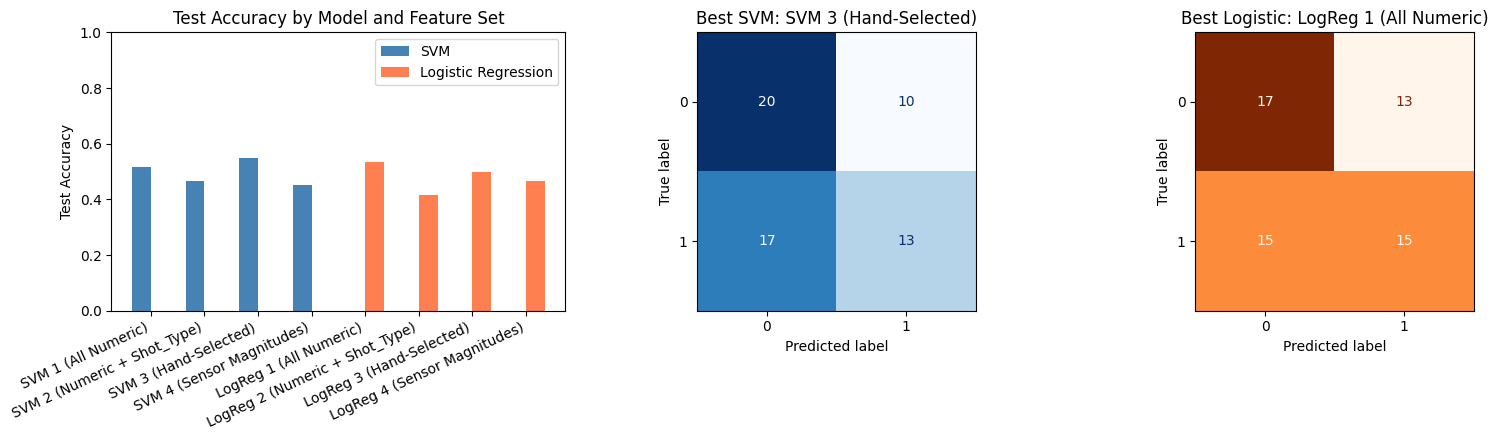

In [18]:
# Identify top-performing previously calculated models
best_svm_name = max(svm_preds, key=lambda k: accuracy_score(svm_test_targets[k], svm_preds[k]))
best_svm_acc = accuracy_score(svm_test_targets[best_svm_name], svm_preds[best_svm_name])

best_lr_name = max(lr_preds, key=lambda k: accuracy_score(lr_test_targets[k], lr_preds[k]))
best_lr_acc = accuracy_score(lr_test_targets[best_lr_name], lr_preds[best_lr_name])

print(f"Top SVM Model: {best_svm_name} (Accuracy: {best_svm_acc:.4f})")
print(classification_report(svm_test_targets[best_svm_name], svm_preds[best_svm_name]))

print(f"Top Logistic Regression Model: {best_lr_name} (Accuracy: {best_lr_acc:.4f})")
print(classification_report(lr_test_targets[best_lr_name], lr_preds[best_lr_name]))

# Create summary_pivot directly from the prediction dictionaries
summary_pivot = pd.DataFrame({
    'SVM': {k: accuracy_score(svm_test_targets[k], svm_preds[k]) for k in svm_preds},
    'Logistic Regression': {k: accuracy_score(lr_test_targets[k], lr_preds[k]) for k in lr_preds}
})

# Comparative Bar Chart & Confusion Matrices using previously calculated results
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Model Comparison Bar Chart
configurations = list(summary_pivot.index)
x_pos = np.arange(len(configurations))
width = 0.35

svm_accs = [summary_pivot.loc[c, 'SVM'] for c in configurations]
lr_accs = [summary_pivot.loc[c, 'Logistic Regression'] for c in configurations]

axes[0].bar(x_pos - width/2, svm_accs, width, label='SVM', color='steelblue')
axes[0].bar(x_pos + width/2, lr_accs, width, label='Logistic Regression', color='coral')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Test Accuracy by Model and Feature Set')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(configurations, rotation=25, ha='right')
axes[0].set_ylim(0, 1.0)
axes[0].legend()

# Confusion Matrix for Best SVM
ConfusionMatrixDisplay.from_predictions(
    svm_test_targets[best_svm_name], svm_preds[best_svm_name], 
    ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title(f'Best SVM: {best_svm_name}')

# Confusion Matrix for Best Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    lr_test_targets[best_lr_name], lr_preds[best_lr_name], 
    ax=axes[2], cmap='Oranges', colorbar=False
)
axes[2].set_title(f'Best Logistic: {best_lr_name}')

plt.tight_layout()
plt.show()